# Netflix Movies and TV Shows: Data Analysis Report

## 1. Introduction

This project analyzes the Netflix Movies and TV Shows dataset to understand the composition and characteristics of Netflix's content library. Python data analysis libraries are used to explore the dataset, prepare the data, identify patterns, create visualizations, and communicate meaningful findings.

## 2. Objectives

- Understand the structure and characteristics of the dataset.
- Identify and handle missing values and duplicate records.
- Analyze movies, TV shows, release years, genres, countries, and content ratings.
- Create visualizations to communicate important patterns.
- Interpret findings and develop evidence-based recommendations.

## 3. Tools and Technologies

- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Descriptive statistics and exploratory data analysis

## 4. Dataset Description

The dataset contains information about Netflix titles, including their unique IDs, content types, titles, directors, cast, countries, dates added, release years, ratings, durations, genres, and descriptions.

## 5. Expected Outcome

A cleaned dataset, a collection of meaningful visualizations, a structured interpretation of the findings, and recommendations for further analysis.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df = pd.read_csv("/content/netflix_titles.csv")


In [6]:


# Display first five rows
display(df.head())

# Dataset size
print("Rows and columns:", df.shape)

# Column names and data types
print(df.info())

# Statistical summary
display(df.describe(include="all").T)

# Missing values
display(df.isnull().sum())

# Duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Unique values
print("Content types:", df["type"].unique())
print("Release years:", df["release_year"].nunique())

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Rows and columns: (8807, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s8807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Zubaan,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


Duplicate rows: 0
Content types: ['Movie' 'TV Show']
Release years: 74


In [7]:
# Create a copy of the original dataset
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Convert date_added into datetime format
clean_df["date_added"] = pd.to_datetime(
    clean_df["date_added"].str.strip(),
    errors="coerce"
)

# Clean text columns
text_columns = [
    "type", "title", "director", "cast", "country",
    "rating", "duration", "listed_in", "description"
]

for col in text_columns:
    clean_df[col] = clean_df[col].replace(r"^\s*$", np.nan, regex=True)

# Fill missing values in selected categorical columns
for col in ["director", "cast", "country", "rating", "duration"]:
    clean_df[col] = clean_df[col].fillna("Unknown")

# Extract year and month when content was added
clean_df["year_added"] = clean_df["date_added"].dt.year
clean_df["month_added"] = clean_df["date_added"].dt.month

# Check cleaning results
print("Dataset shape:", clean_df.shape)
print("\nMissing values:")
print(clean_df.isnull().sum())
print("\nDuplicate rows:", clean_df.duplicated().sum())

# Save cleaned dataset
clean_df.to_csv("netflix_cleaned.csv", index=False)

Dataset shape: (8807, 14)

Missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
year_added      10
month_added     10
dtype: int64

Duplicate rows: 0


,count
type,
Movie,6131
TV Show,2676


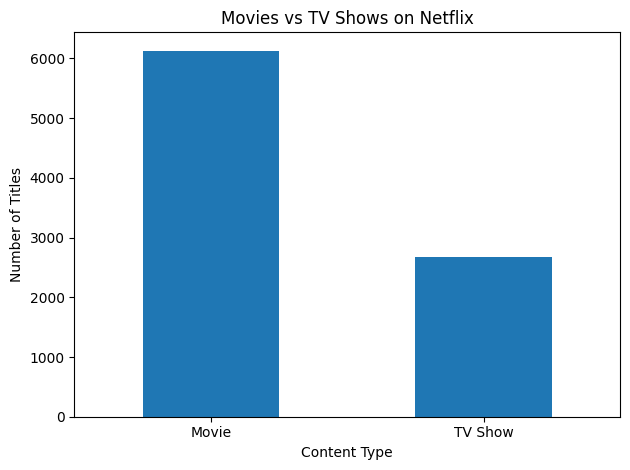

In [8]:
content_counts = clean_df["type"].value_counts()

display(content_counts)

content_counts.plot(
    kind="bar",
    title="Movies vs TV Shows on Netflix",
    xlabel="Content Type",
    ylabel="Number of Titles"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

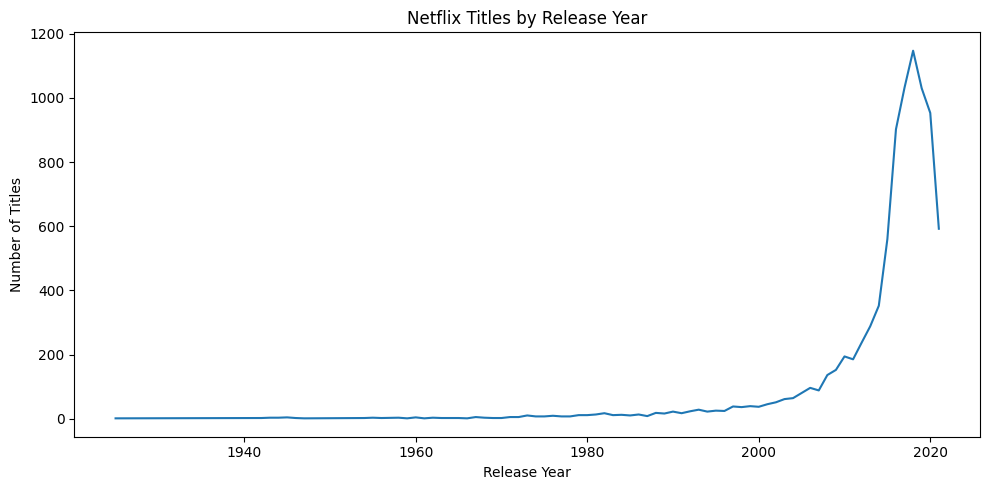

In [9]:
year_counts = (
    clean_df["release_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

year_counts.plot(
    kind="line",
    figsize=(10, 5),
    title="Netflix Titles by Release Year",
    xlabel="Release Year",
    ylabel="Number of Titles"
)
plt.tight_layout()
plt.show()

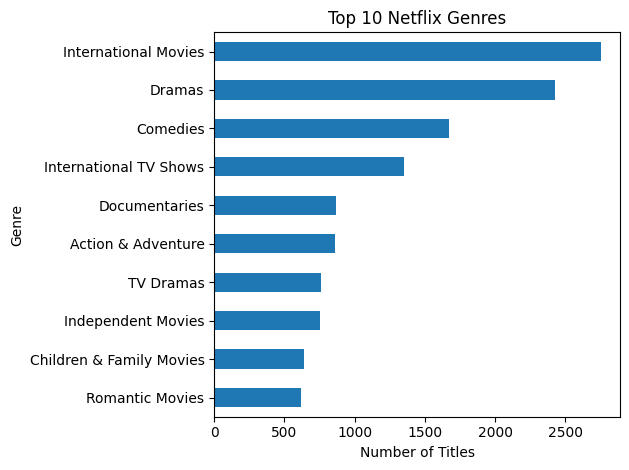

In [10]:
genres = (
    clean_df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
)

top_genres = genres.value_counts().head(10)

top_genres.plot(
    kind="barh",
    title="Top 10 Netflix Genres",
    xlabel="Number of Titles",
    ylabel="Genre"
)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

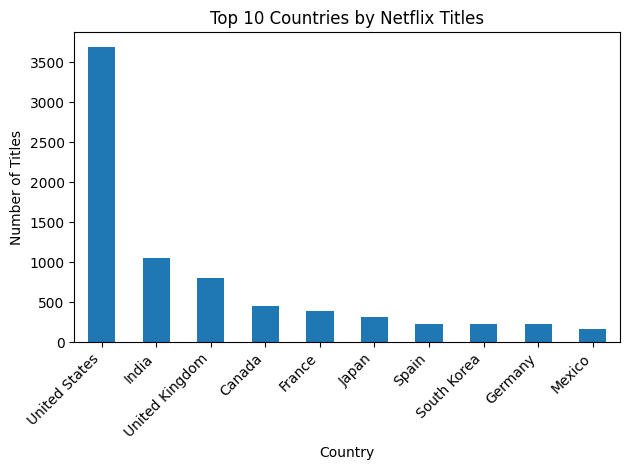

In [11]:
countries = (
    clean_df["country"]
    .dropna()
    .str.split(", ")
    .explode()
)

countries = countries[countries != "Unknown"]
top_countries = countries.value_counts().head(10)

top_countries.plot(
    kind="bar",
    title="Top 10 Countries by Netflix Titles",
    xlabel="Country",
    ylabel="Number of Titles"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

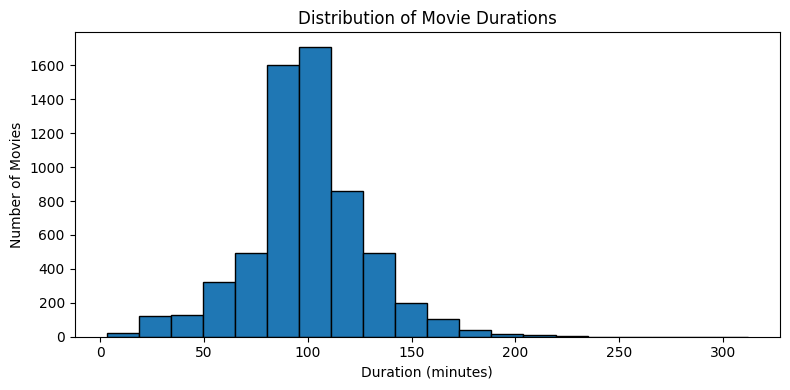

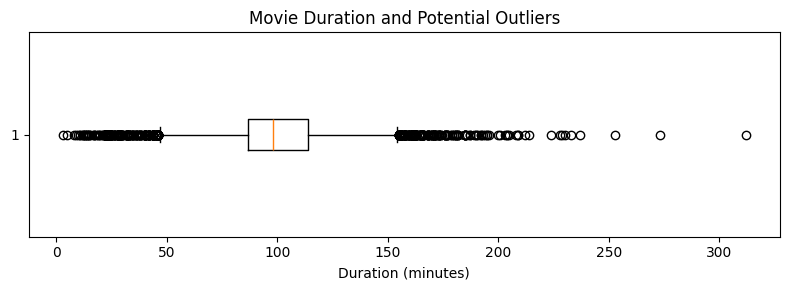

In [13]:
# Extract movie duration in minutes
movie_minutes = pd.to_numeric(
    clean_df.loc[clean_df["type"] == "Movie", "duration"]
    .str.extract(r"(\d+)", expand=False),
    errors="coerce"
).dropna()

# Histogram
plt.figure(figsize=(8, 4))
plt.hist(movie_minutes, bins=20, edgecolor="black")
plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

# Box plot
plt.figure(figsize=(8, 3))
plt.boxplot(movie_minutes, vert=False)
plt.title("Movie Duration and Potential Outliers")
plt.xlabel("Duration (minutes)")
plt.tight_layout()
plt.show()

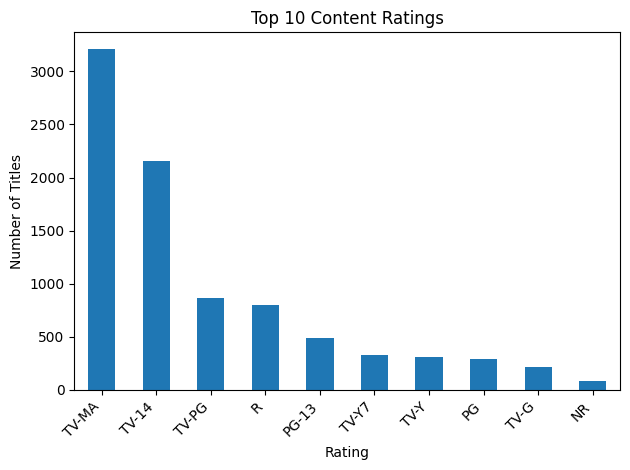

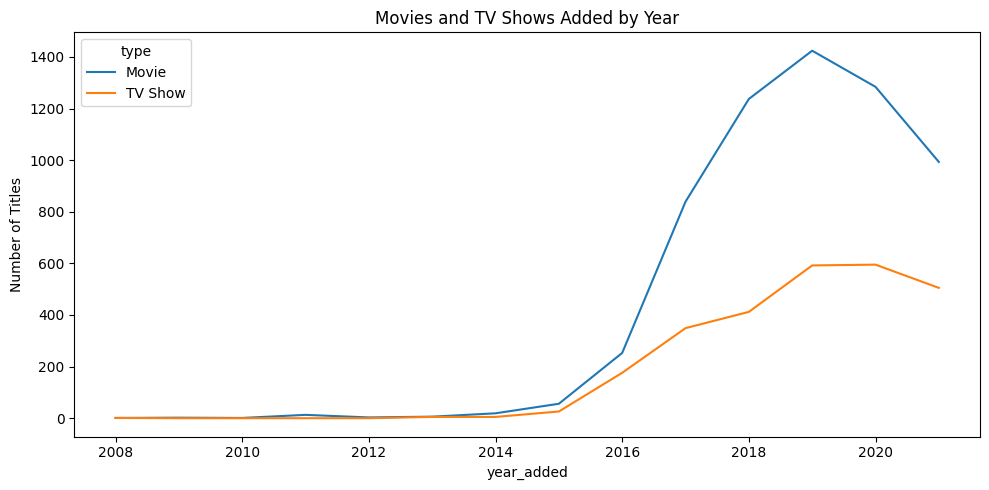

In [14]:
# Content ratings
rating_counts = clean_df["rating"].value_counts().head(10)

rating_counts.plot(
    kind="bar",
    title="Top 10 Content Ratings",
    xlabel="Rating",
    ylabel="Number of Titles"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Compare content types by year added
year_type = pd.crosstab(
    clean_df["year_added"],
    clean_df["type"]
)

year_type.plot(
    kind="line",
    figsize=(10, 5),
    title="Movies and TV Shows Added by Year"
)
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()


,Number of Titles
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


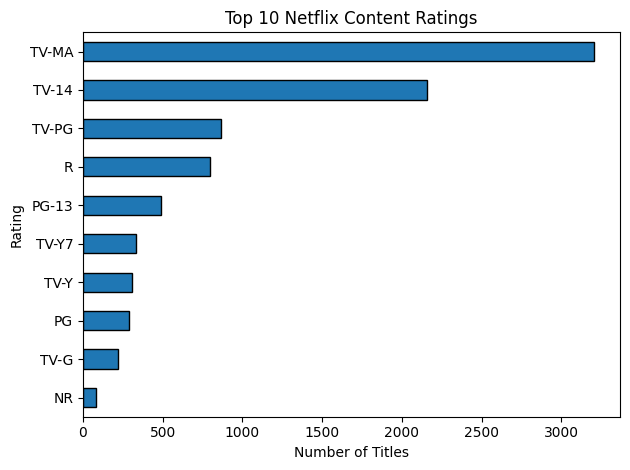

Most frequent rating: TV-MA
Number of titles: 3207

Interpretation: The chart shows the frequency of content classifications. It does not establish audience preferences.


In [15]:
rating_counts = clean_df["rating"].dropna().value_counts().head(10)

display(rating_counts.to_frame("Number of Titles"))

rating_counts.sort_values().plot(kind="barh", edgecolor="black")
plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

if not rating_counts.empty:
    print("Most frequent rating:", rating_counts.index[0])
    print("Number of titles:", int(rating_counts.iloc[0]))

    print(
        "\nInterpretation: The chart shows the frequency of content "
        "classifications. It does not establish audience preferences."
    )

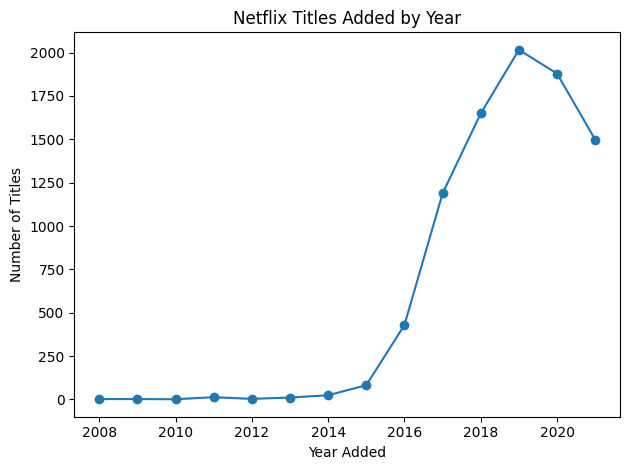

Year with the most additions: 2019
Titles added in that year: 2016

Interpretation: This chart describes additions represented in the dataset. It may not represent the complete historical catalog or current Netflix availability.


In [16]:
added_by_year = clean_df["year_added"].dropna().astype(int).value_counts().sort_index()

if not added_by_year.empty:
    added_by_year.plot(kind="line", marker="o")
    plt.title("Netflix Titles Added by Year")
    plt.xlabel("Year Added")
    plt.ylabel("Number of Titles")
    plt.tight_layout()
    plt.show()

    print("Year with the most additions:", int(added_by_year.idxmax()))
    print("Titles added in that year:", int(added_by_year.max()))

    print(
        "\nInterpretation: This chart describes additions represented in "
        "the dataset. It may not represent the complete historical catalog "
        "or current Netflix availability."
    )
else:
    print("No valid dates are available for this analysis.")

In [18]:
# CELL 14: CONCLUSIONS AND RECOMMENDATIONS

# Ensure the cleaned dataset exists
if "clean_df" not in globals():
    raise ValueError("Please run Cells 1–13 first.")

total_titles = len(clean_df)

# Calculate content type counts safely
if "type" in clean_df.columns:
    content_counts = clean_df["type"].value_counts()
    movies = int(content_counts.get("Movie", 0))
    tv_shows = int(content_counts.get("TV Show", 0))
else:
    movies, tv_shows = 0, 0

movie_percentage = (
    movies / total_titles * 100 if total_titles > 0 else 0
)
tv_percentage = (
    tv_shows / total_titles * 100 if total_titles > 0 else 0
)

print("=" * 60)
print("NETFLIX DATA ANALYSIS: CONCLUSION")
print("=" * 60)

print(f"\nTotal records analyzed: {total_titles:,}")
print(f"Movies: {movies:,} ({movie_percentage:.2f}%)")
print(f"TV Shows: {tv_shows:,} ({tv_percentage:.2f}%)")

print("\nCONCLUSION")
print("-" * 60)

if total_titles > 0:
    print(
        "The Netflix dataset was explored and cleaned using Python, "
        "Pandas, and NumPy. Visualizations and descriptive statistics "
        "were used to investigate content types, release years, genres, "
        "countries, ratings, and movie durations where available."
    )
    if movies > tv_shows:
        print("Movies represent the larger content category.")
    elif tv_shows > movies:
        print("TV Shows represent the larger content category.")
    else:
        print("Movies and TV Shows have equal record counts.")
else:
    print("The dataset is empty. Load the dataset before analysis.")

print("\nRECOMMENDATIONS")
print("-" * 60)

recommendations = [
    "Improve the completeness and consistency of content metadata.",
    "Analyze genre and country distributions to understand catalog variety.",
    "Investigate release-year and content-addition trends.",
    "Review potential duration outliers before deciding whether they are errors.",
    "Use viewership and engagement data for future audience-preference analysis."
]

for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")

print("\nLIMITATION")
print("-" * 60)
print(
    "This dataset describes content metadata. It does not directly "
    "measure audience preferences, viewing figures, or profitability."
)

NETFLIX DATA ANALYSIS: CONCLUSION

Total records analyzed: 8,807
Movies: 6,131 (69.62%)
TV Shows: 2,676 (30.38%)

CONCLUSION
------------------------------------------------------------
The Netflix dataset was explored and cleaned using Python, Pandas, and NumPy. Visualizations and descriptive statistics were used to investigate content types, release years, genres, countries, ratings, and movie durations where available.
Movies represent the larger content category.

RECOMMENDATIONS
------------------------------------------------------------
1. Improve the completeness and consistency of content metadata.
2. Analyze genre and country distributions to understand catalog variety.
3. Investigate release-year and content-addition trends.
4. Review potential duration outliers before deciding whether they are errors.
5. Use viewership and engagement data for future audience-preference analysis.

LIMITATION
------------------------------------------------------------
This dataset describes 

In [19]:
# CELL 15: SAVE AND DOWNLOAD FILES

from pathlib import Path
from google.colab import files

# Validate that the cleaned dataset exists
if "clean_df" not in globals():
    raise ValueError("Please run the data cleaning cell first.")

output_dir = Path("/content")
csv_path = output_dir / "netflix_cleaned.csv"
report_path = output_dir / "Netflix_Analysis_Report.md"

# Save the cleaned dataset
clean_df.to_csv(csv_path, index=False)

# Build a report using available dataset columns
report = [
    "# Netflix Movies and TV Shows - Data Analysis Report",
    "",
    "## 1. Objective",
    "Analyze Netflix content metadata to discover patterns and insights.",
    "",
    "## 2. Methodology",
    "- Dataset loading and exploration",
    "- Data cleaning and preprocessing",
    "- Exploratory data analysis",
    "- Data visualization",
    "- Interpretation and recommendations",
    "",
    "## 3. Dataset Overview",
    f"- Number of records: {len(clean_df):,}",
    f"- Number of columns: {len(clean_df.columns):,}",
    "",
    "## 4. Data Quality",
    f"- Duplicate rows remaining: {int(clean_df.duplicated().sum()):,}",
    f"- Total missing cells: {int(clean_df.isnull().sum().sum()):,}",
    "",
    "### Missing values by column",
    "",
    "| Column | Missing values |",
    "|---|---:|",
]

for column in clean_df.columns:
    missing = int(clean_df[column].isnull().sum())
    report.append(f"| {column} | {missing} |")

report.extend([
    "",
    "## 5. Content Type Analysis",
    ""
])

if "type" in clean_df.columns:
    counts = clean_df["type"].value_counts()
    for label, count in counts.items():
        percentage = count / len(clean_df) * 100 if len(clean_df) else 0
        report.append(
            f"- {label}: {int(count):,} titles ({percentage:.2f}%)"
        )
else:
    report.append("Content type information is unavailable.")

report.extend([
    "",
    "## 6. Key Findings",
    "",
    "Review the charts and printed findings in the Colab notebook. "
    "Only report patterns supported by the actual dataset.",
    "",
    "## 7. Conclusions",
    "",
    "The analysis examines the composition and metadata of Netflix's "
    "content library. Data cleaning and visualization help identify "
    "content distributions and data quality issues.",
    "",
    "## 8. Recommendations",
    "",
    "1. Improve missing and inconsistent metadata where possible.",
    "2. Explore genre and country distributions.",
    "3. Investigate release-year and content-addition trends.",
    "4. Investigate unusual durations before treating them as errors.",
    "5. Combine metadata with viewership data before making claims "
    "about audience preferences or business performance.",
    "",
    "## 9. Limitations",
    "",
    "The dataset does not directly provide streaming figures, viewer "
    "engagement, or profitability. Conclusions should remain limited "
    "to the information available."
])

# Write the report
report_path.write_text("\n".join(report), encoding="utf-8")

# Confirm the files were created
print("Files created successfully:")
print(f"1. {csv_path}")
print(f"2. {report_path}")

print("\nDownloading the analysis report...")
files.download(str(report_path))

print("Downloading the cleaned dataset...")
files.download(str(csv_path))

Files created successfully:
1. /content/netflix_cleaned.csv
2. /content/Netflix_Analysis_Report.md



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>